# Paraphrase test: do LLMs change post-2023 texts less than older ones?

If texts written after ChatGPT's release already read like LLM output, an LLM paraphrase should change them
**less** than older texts (the Raidar idea, Mao et al. 2024, applied across years). Seven open models
paraphrased the same 15,357 texts: 5,757 ACL papers (2013–2024) and 9,600 AO3 chapters (The Lord of the
Rings 2009–2026, The Hobbit 2013–2026). This notebook shows how far each paraphrase moved from its original,
and whether that distance drops after the break (2023), beyond the trend before it.

It reads the outputs of `biber-drift paraphrase analyze` (`outputs/paraphrase/analysis/main/`) and the
tagging records (`outputs/paraphrase/features/main/`); nothing is recomputed here. After a change to the
analysis, rerun `biber-drift paraphrase analyze` first. **No paper, chapter or paraphrase text is printed**,
only ids, counts and statistics.

1. The design: texts, models, filters
2. How much each model changes a text
3. Change by year
4. Interrupted time series
5. Regressions: the post-2023 effect per model and pooled
6. Sensitivity checks
7. Cohort MMD²
8. Which features the models change
9. Summary, and what is still open

**How to read the measures.** All compare a text's original window (400–440 words) with its cleaned
paraphrase, cut the same way:

| measure | what it is | less change after 2023 shows as |
|---|---|---|
| `biber` | Euclidean distance of the 67 (AO3: 66) z-scored Biber features | a drop |
| `biber_no_f43` | the same without `f_43` (MATTR), so outputs under 100 tokens count too | a drop |
| `dimensions` | distance of the Biber Dimension 1–6 scores | a drop |
| `edit` | word-level edit distance divided by the original's words | a drop |
| `overlap` | share of the original's 8-word sequences kept | a rise |

Features are z-scored on each pipeline run's scaler (`outputs/{acl,ao3}/results/reference_scaler.csv`),
except `f_43`, which here is the moving-average type-token ratio over 100 tokens and is scaled on the
re-tagged originals of its corpus. Means are weighted to each group's overall stratum mix (venue tier or
rating), so a year with another mix (ACL 2013, LotR 2009) does not move the series.

**Models.** Claims rest on the five `main` families (Llama 3.1, Mistral NeMo, Gemma 3, gpt-oss, OLMo 2),
each reported on its own. Qwen3 is reported separately because it copies most texts, and Llama 2 is a
check: its pretraining data ends before ChatGPT.

In [1]:
from pathlib import Path
import inspect
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from biber_drift.paraphrase import load_paraphrase_config  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 60)

CONFIG = load_paraphrase_config(ROOT / "configs/paraphrase.yaml")
PARAPHRASE = ROOT / "outputs/paraphrase"
RESULTS = PARAPHRASE / "analysis/main"
FEATURES = PARAPHRASE / "features/main"

MODELS = list(CONFIG.models)                                   # config order
ROLE = {key: model.role for key, model in CONFIG.models.items()}
MAIN = [key for key in MODELS if ROLE[key] == "main"]
LABEL = {"llama-3.1-8b": "Llama 3.1 8B", "qwen3-8b": "Qwen3 8B", "mistral-nemo-12b": "Mistral NeMo 12B",
         "gemma-3-12b": "Gemma 3 12B", "gpt-oss-20b": "gpt-oss 20B", "olmo-2-13b": "OLMo 2 13B",
         "llama-2-13b": "Llama 2 13B"}
GROUPS = {"acl": "ACL", "lotr": "AO3 LotR", "hobbit": "AO3 Hobbit"}
MEASURE = {"biber": "Biber distance", "biber_no_f43": "Biber distance (no f_43)",
           "dimensions": "Dimension 1–6 distance", "edit": "edit rate", "overlap": "overlap (8-grams kept)"}

# Five categorical hues in a validated order (colour-blind safe as adjacent lines); the two reference
# models are grey and dashed, so they never compete with the main families.
COLOR = dict(zip(MAIN, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
COLOR |= {"qwen3-8b": "#898781", "llama-2-13b": "#52514e"}
DASH = {key: "-" for key in MAIN} | {"qwen3-8b": ":", "llama-2-13b": "--"}
DIVERGING = LinearSegmentedColormap.from_list("change", ["#1c5cab", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 11, "axes.titleweight": "normal", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": "#898781", "ytick.color": "#898781", "xtick.labelcolor": "#52514e",
    "ytick.labelcolor": "#52514e", "text.color": "#0b0b0b", "legend.frameon": False,
    "lines.linewidth": 1.6, "font.size": 10, "figure.dpi": 110,
})


def model_label(key):
    return LABEL[key] + ("" if ROLE[key] == "main" else f" ({ROLE[key]})")


def model_legend(fig, models=MODELS, y=-0.04):
    handles = [Line2D([], [], color=COLOR[m], ls=DASH[m], lw=2, label=model_label(m)) for m in models]
    fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, y), fontsize=9)


def mark_break(ax, at):
    ax.axvline(at, color="#898781", lw=0.9, ls=(0, (4, 3)), zorder=0)


def stars(p):
    return "" if pd.isna(p) else "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def cell(estimate, p, digits=3):
    return f"{estimate:+.{digits}f}{stars(p)}"

In [2]:
yearly = pd.read_csv(RESULTS / "yearly.csv")
its = pd.read_csv(RESULTS / "trend/its.csv")
series = pd.read_csv(RESULTS / "trend/series.csv")
regressions = pd.read_csv(RESULTS / "regressions.csv")
features_yearly = pd.read_csv(RESULTS / "features_yearly.csv")
cohorts = pd.read_csv(RESULTS / "mmd/cohorts.csv")
mmd_its = pd.read_csv(RESULTS / "mmd/its.csv")
info = json.loads((RESULTS / "analysis.json").read_text())
texts = pd.concat([pd.read_parquet(RESULTS / "texts" / f"{key}.parquet").assign(model=key) for key in MODELS],
                  ignore_index=True)
print(f"{len(texts):,} measured paraphrases ({texts['item_id'].nunique():,} texts x {len(MODELS)} models)")

107,407 measured paraphrases (15,357 texts x 7 models)


---
## 1. The design: texts, models, filters

The same texts go to every model: a fixed number per year, with the same venue-tier (ACL) or rating (AO3)
mix every year. Only ACL 2013 (257 papers in all) and LotR 2009 (only 46 Teen works) deviate.

In [3]:
counts = pd.read_csv(PARAPHRASE / "sample_counts.csv")
table = counts.pivot_table(index="year", columns="group", values="documents", aggfunc="sum")[list(GROUPS)]
display(table.rename(columns=GROUPS).fillna(0).astype(int).T)
strata = counts.groupby("group")[["A*", "Conference", "Workshop", "General Audiences", "Teen And Up Audiences"]].sum()
shares = (strata.div(strata.sum(axis=1), axis=0) * 100).loc[list(GROUPS)].rename(index=GROUPS)
print("Stratum shares per group, % (the weights of the yearly means)")
display(shares.replace(0.0, np.nan).dropna(axis=1, how="all").map(lambda v: "" if pd.isna(v) else f"{v:.1f}"))

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
group,,,,,,,,,,,,,,,,,,
ACL,0,0,0,0,257,500,500,500,500,500,500,500,500,500,500,500,0,0
AO3 LotR,300,300,300,300,300,300,300,300,300,300,300,300,300,300,300,300,300,300
AO3 Hobbit,0,0,0,0,300,300,300,300,300,300,300,300,300,300,300,300,300,300


Stratum shares per group, % (the weights of the yearly means)


,A*,Conference,Workshop,General Audiences,Teen And Up Audiences
group,,,,,
ACL,36.8,35.4,27.8,,
AO3 LotR,,,,53.1,46.9
AO3 Hobbit,,,,42.7,57.3


Every model saw every text. The check dropped outputs that are no paraphrase (missing, cut off, refusals,
template remnants, loops); short, long and copied outputs stay in, because they are amounts of change, the
thing measured. `f_43` is missing where an output has under 100 tokens.

In [4]:
rows = []
for key in MODELS:
    items = pd.read_parquet(FEATURES / f"{key}.items.parquet")
    tagged = json.loads((FEATURES / f"{key}.json").read_text())
    kept = items[items["kept"]]
    rows.append({"model": model_label(key), "kept": int(items["kept"].sum()), "dropped": int((~items["kept"]).sum()),
                 "no f_43": tagged["f_43_missing"],
                 "short / long / copy": f"{kept['short'].sum()} / {kept['long'].sum()} / {kept['copy'].sum()}",
                 "median length ratio": kept["length_ratio"].median(),
                 "kept without short/long/copy": info["texts"]["without_short_long_copy"][key]})
display(pd.DataFrame(rows).set_index("model").round({"median length ratio": 2}))
print("f_43 (MATTR) scale from the re-tagged originals:",
      {corpus: f"mean {v['mean']:.4f}, sd {v['std']:.4f}" for corpus, v in info["f_43"].items()})

,kept,dropped,no f_43,short / long / copy,median length ratio,kept without short/long/copy
model,,,,,,
Llama 3.1 8B,15333,24,5,607 / 3 / 136,0.83,14588
Qwen3 8B (separate),15345,12,5,19 / 0 / 11201,1.00,4125
Mistral NeMo 12B,15351,6,14,556 / 0 / 1,0.79,14794
Gemma 3 12B,15353,4,0,25 / 0 / 20,0.96,15308
gpt-oss 20B,15347,10,2,30 / 17 / 2114,0.97,13199
OLMo 2 13B,15343,14,0,12 / 4 / 2,0.93,15325
Llama 2 13B (check),15335,22,333,8223 / 0 / 0,0.48,7112


f_43 (MATTR) scale from the re-tagged originals: {'acl': 'mean 0.7323, sd 0.0367', 'ao3': 'mean 0.7372, sd 0.0320'}


<!-- obs:design -->
**What we see:**
- Every model answered all 15,357 texts; the check dropped only 4–24 per model (refusals, cut-offs, loops).
- **Llama 2 condenses:** median length ratio 0.48, and 8,223 of its outputs are under half the original's
  length. It also accounts for most outputs without `f_43` (333; Mistral 14, the rest ≤ 5).
- **Qwen3 copies:** 11,201 of its 15,345 outputs keep at least 80% of the original's 8-word sequences. gpt-oss
  copies 2,114, almost all of them AO3 chapters. Without short, long and copied outputs, Qwen3 keeps 4,125
  texts and Llama 2 7,112; the five main models keep 13,199–15,325.
- MATTR (`f_43`) is scaled on the originals: ACL mean 0.732 (sd 0.037), AO3 0.737 (sd 0.032).

---
## 2. How much each model changes a text

Medians over all kept texts, per corpus. The distances are in z-score units of the run's scaler.

In [5]:
medians = texts.groupby(["corpus", "model"])[list(MEASURE)].median()
medians = medians.rename(index=lambda m: model_label(m) if m in LABEL else m, level="model")
display(medians.unstack("corpus").swaplevel(axis=1).sort_index(axis=1, level=0)
        .reindex([model_label(m) for m in MODELS]).round(2))

corpus                acl                                          ao3                                      
                    biber biber_no_f43 dimensions  edit overlap  biber biber_no_f43 dimensions  edit overlap
model                                                                                                       
Llama 3.1 8B         6.48         6.43       3.17  0.42    0.18   8.75         8.69       5.12  0.69    0.03
Qwen3 8B (separate)  2.64         2.63       1.10  0.08    0.75   0.08         0.08       0.05  0.00    0.99
Mistral NeMo 12B     8.08         7.99       4.30  0.50    0.06   7.88         7.80       4.70  0.61    0.02
Gemma 3 12B          8.76         8.66       5.03  0.59    0.02   6.08         6.04       3.07  0.44    0.06
gpt-oss 20B          7.27         7.17       3.38  0.45    0.06   3.62         3.60       1.58  0.16    0.48
OLMo 2 13B           7.29         7.23       3.93  0.54    0.03   7.83         7.78       5.63  0.58    0.02
Llama 2 13B (check)  9.53         9.47       4.90  0.73    0.04  11.24        11.26       7.17  0.83    0.00

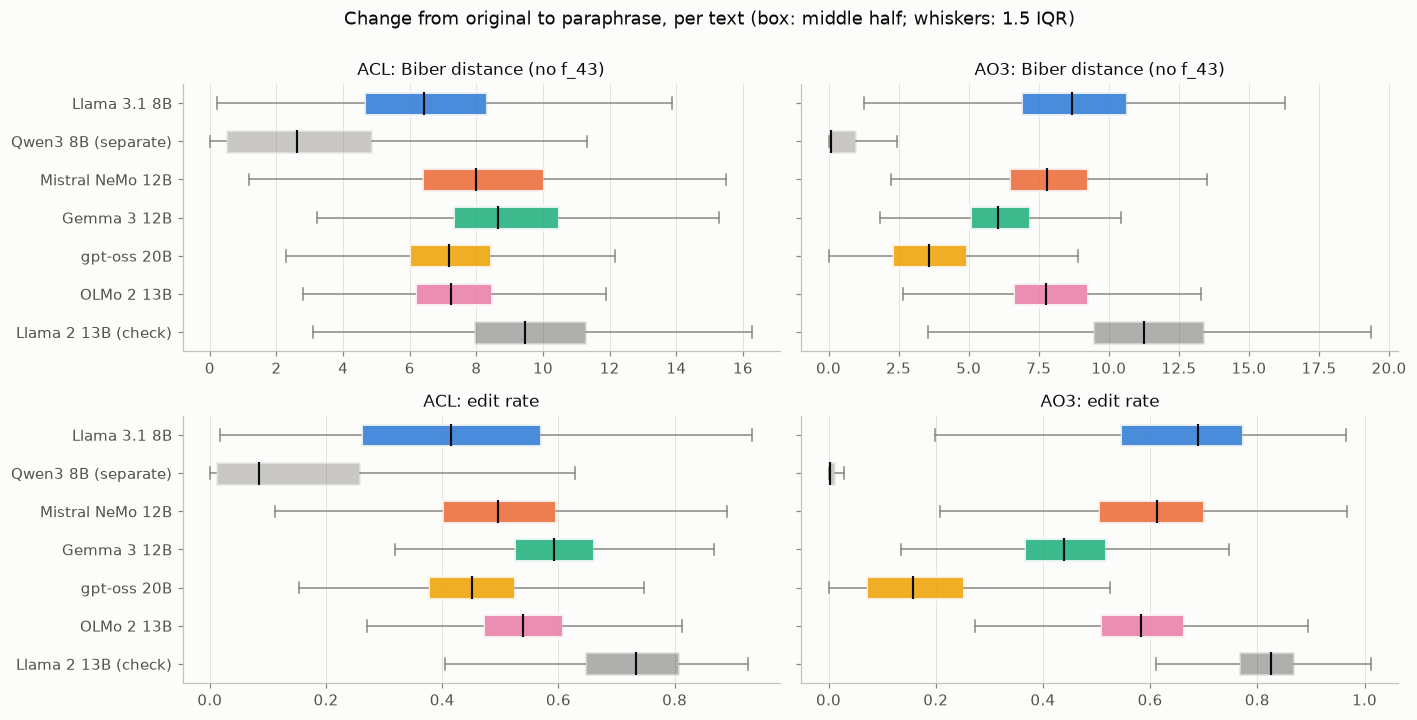

In [6]:
# matplotlib >= 3.10 takes orientation=, older versions vert=
HORIZONTAL = ({"orientation": "horizontal"} if "orientation" in inspect.signature(plt.Axes.boxplot).parameters
              else {"vert": False})
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharey=True)
for col, corpus in enumerate(["acl", "ao3"]):
    for row, measure in enumerate(["biber_no_f43", "edit"]):
        ax = axes[row, col]
        data = [texts.loc[(texts["corpus"] == corpus) & (texts["model"] == m), measure].dropna() for m in MODELS]
        parts = ax.boxplot(data, **HORIZONTAL, widths=0.6, showfliers=False, patch_artist=True,
                           medianprops={"color": "#0b0b0b", "lw": 1.4}, whiskerprops={"color": "#898781"},
                           capprops={"color": "#898781"})
        for patch, m in zip(parts["boxes"], MODELS):
            patch.set(facecolor=COLOR[m], alpha=0.85 if ROLE[m] == "main" else 0.45, edgecolor="#fcfcfb", lw=2)
        ax.set_yticks(range(1, len(MODELS) + 1), [model_label(m) for m in MODELS])
        ax.grid(axis="y", visible=False)
        ax.set_title(f"{corpus.upper()}: {MEASURE[measure]}")
axes[0, 0].invert_yaxis()                                     # shared axis: invert once
fig.suptitle("Change from original to paraphrase, per text (box: middle half; whiskers: 1.5 IQR)", y=1.0)
fig.tight_layout()
plt.show()

<!-- obs:amount -->
**What we see:**
- The main models rewrite a lot: median Biber distance 6.4–8.7 (ACL) and 3.6–8.7 (AO3) z-units, and they
  change 42–59% of an ACL paper's words.
- **gpt-oss is light on fiction:** in AO3 it changes 16% of the words and keeps half the 8-grams (overlap 0.48),
  against 45% and 0.06 in ACL.
- **Gemma** changes ACL papers the most among the main models (8.66; 59% of words), AO3 chapters less (6.04).
- **Qwen3 hardly touches AO3** (median edit rate 0.00, overlap 0.99) and changes ACL papers little (0.08).
- **Llama 2 changes most** (ACL 9.47, AO3 11.26; 73% and 83% of words), largely because it shortens.

---
## 3. Change by year

Stratum-weighted yearly means with stratified bootstrap 95% intervals (bands, main models only). The dashed
vertical line marks the break: 2023 is the first year after ChatGPT's release (30 Nov 2022). If newer texts
already read like LLM output, the lines should fall after it, beyond their earlier course.

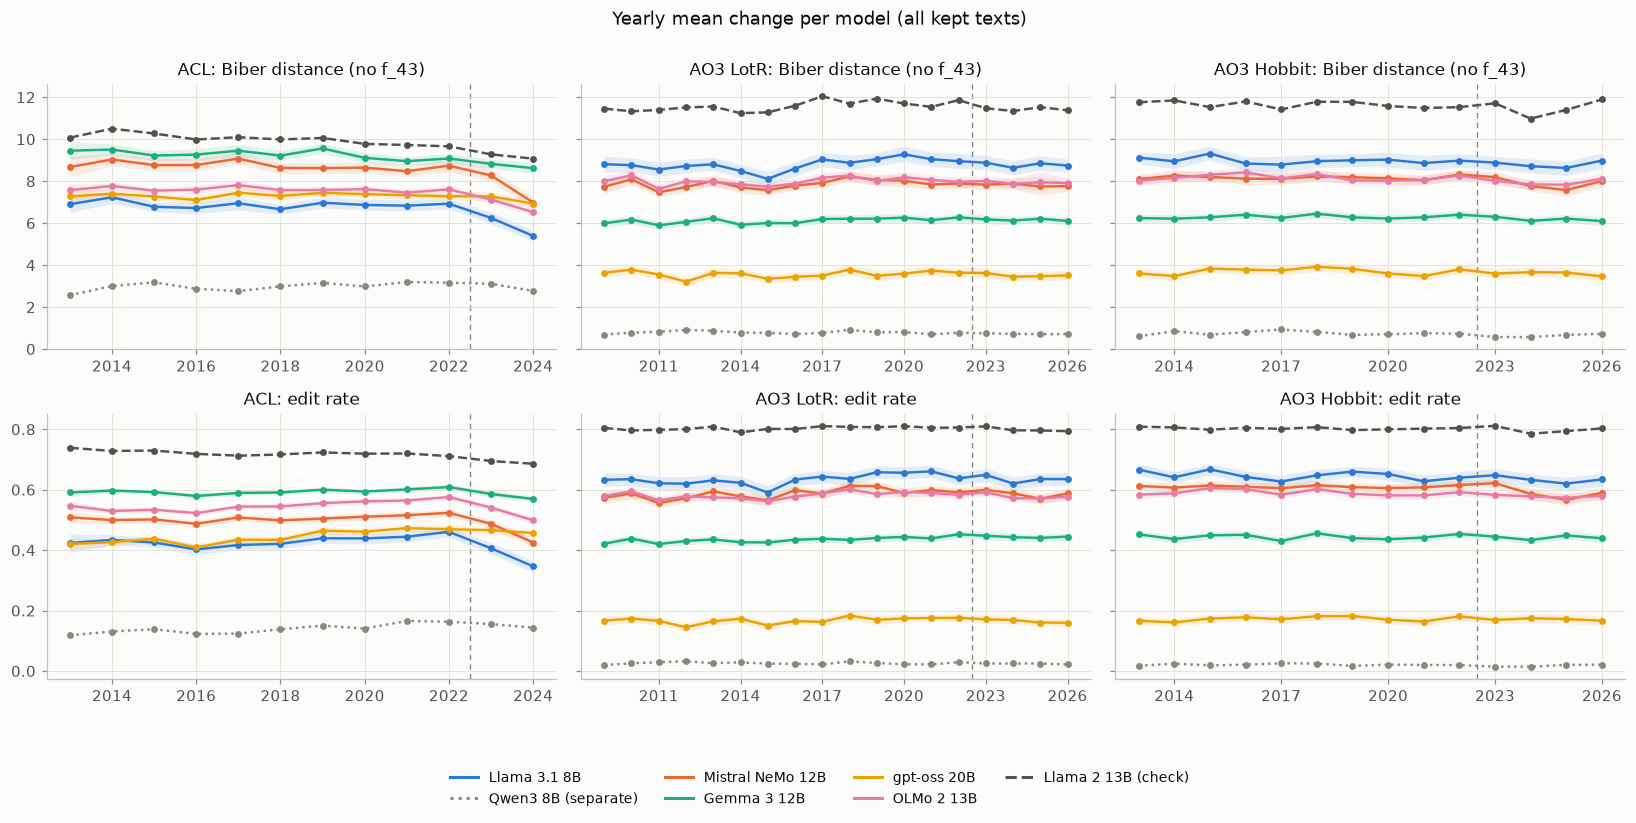

In [7]:
def yearly_panels(measures, variant="all", title=""):
    data = yearly[yearly["variant"] == variant]
    fig, axes = plt.subplots(len(measures), 3, figsize=(15, 3.4 * len(measures)), sharey="row", squeeze=False)
    for row, measure in enumerate(measures):
        for col, group in enumerate(GROUPS):
            ax = axes[row, col]
            cell_data = data[(data["measure"] == measure) & (data["group"] == group)]
            for m in MODELS:
                line = cell_data[cell_data["model"] == m].sort_values("year")
                if ROLE[m] == "main":
                    ax.fill_between(line["year"], line["ci_lower"], line["ci_upper"], color=COLOR[m], alpha=0.12, lw=0)
                ax.plot(line["year"], line["mean"], color=COLOR[m], ls=DASH[m], marker="o", ms=3.5)
            mark_break(ax, 2022.5)
            ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
            ax.set_title(f"{GROUPS[group]}: {MEASURE[measure]}")
    fig.suptitle(title, y=1.0)
    model_legend(fig, y=0.0)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()


yearly_panels(["biber_no_f43", "edit"], title="Yearly mean change per model (all kept texts)")

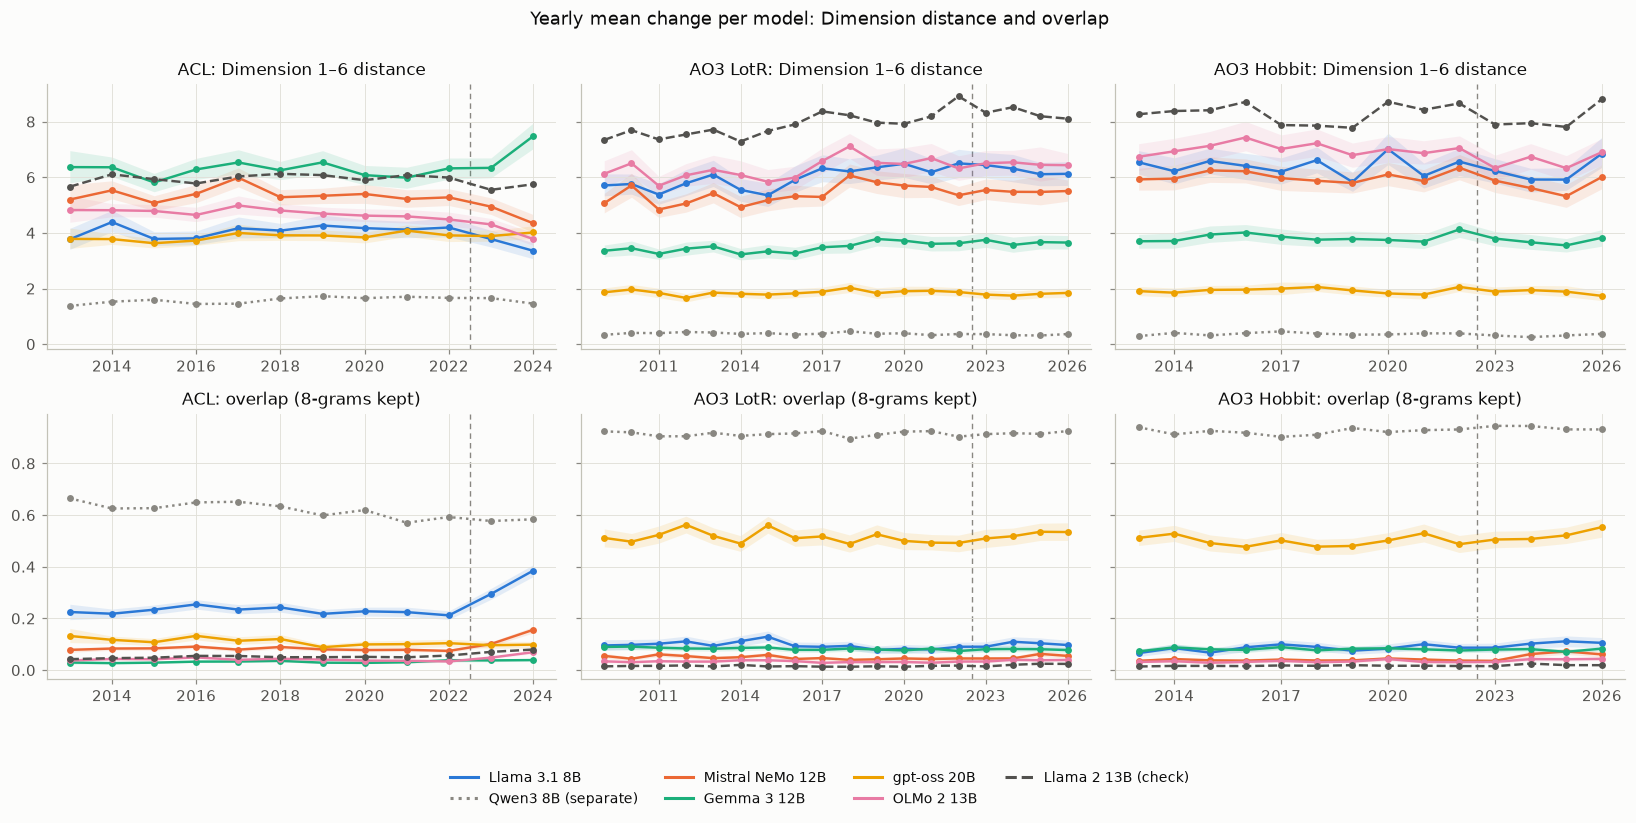

In [8]:
yearly_panels(["dimensions", "overlap"], title="Yearly mean change per model: Dimension distance and overlap")

The same numbers as a table: ACL, last six years, Biber distance without `f_43` and edit rate.

In [9]:
acl_recent = yearly[(yearly["variant"] == "all") & (yearly["group"] == "acl") & (yearly["year"] >= 2019)
                    & yearly["measure"].isin(["biber_no_f43", "edit"])]
table = acl_recent.pivot_table(index=["measure", "model"], columns="year", values="mean")
table = table.reindex([(meas, m) for meas in ["biber_no_f43", "edit"] for m in MODELS])
table.index = [f"{MEASURE[meas]} | {model_label(m)}" for meas, m in table.index]
display(table.round(3))

year,2019,2020,2021,2022,2023,2024
Biber distance (no f_43) | Llama 3.1 8B,6.973,6.868,6.832,6.927,6.247,5.392
Biber distance (no f_43) | Qwen3 8B (separate),3.152,2.982,3.195,3.163,3.110,2.770
Biber distance (no f_43) | Mistral NeMo 12B,8.622,8.645,8.475,8.739,8.272,6.982
Biber distance (no f_43) | Gemma 3 12B,9.559,9.112,8.953,9.080,8.826,8.621
Biber distance (no f_43) | gpt-oss 20B,7.445,7.381,7.332,7.281,7.277,6.930
Biber distance (no f_43) | OLMo 2 13B,7.578,7.621,7.454,7.609,7.124,6.521
Biber distance (no f_43) | Llama 2 13B (check),10.058,9.777,9.724,9.659,9.278,9.072
edit rate | Llama 3.1 8B,0.439,0.439,0.445,0.461,0.406,0.346
edit rate | Qwen3 8B (separate),0.150,0.140,0.166,0.163,0.155,0.144
edit rate | Mistral NeMo 12B,0.505,0.511,0.516,0.523,0.487,0.425


In [10]:
main_its = its[(its["variant"] == "all") & its["measure"].isin(["biber_no_f43", "edit", "overlap"])].copy()
main_its["cell"] = [f"{cell(r.level_change, r.level_p_adjusted)} (placebo {r.placebo_p:.2f})"
                    for r in main_its.itertuples()]
table = main_its.pivot_table(index=["group", "model"], columns="measure", values="cell", aggfunc="first")
table = table.reindex([(g, m) for g in GROUPS for m in MODELS])[["biber_no_f43", "edit", "overlap"]]
table.index = [f"{GROUPS[g]} | {model_label(m)}" for g, m in table.index]
display(table.rename(columns=MEASURE))
for variant, rows in its.groupby("variant"):
    print(f"{variant}: {int((rows['level_p_adjusted'] < 0.05).sum())} of {len(rows)} series with adjusted p < 0.05")

measure,Biber distance (no f_43),edit rate,overlap (8-grams kept)
ACL | Llama 3.1 8B,-0.974* (placebo 0.14),-0.073* (placebo 0.29),+0.115* (placebo 0.14)
ACL | Qwen3 8B (separate),-0.280 (placebo 0.29),-0.016 (placebo 0.43),+0.002 (placebo 1.00)
ACL | Mistral NeMo 12B,-0.896 (placebo 0.14),-0.059* (placebo 0.14),+0.049* (placebo 0.14)
ACL | Gemma 3 12B,-0.294 (placebo 0.29),-0.026 (placebo 0.29),+0.004 (placebo 0.29)
ACL | gpt-oss 20B,-0.244 (placebo 0.29),-0.019 (placebo 0.43),+0.005 (placebo 0.71)
ACL | OLMo 2 13B,-0.704* (placebo 0.14),-0.053* (placebo 0.14),+0.023* (placebo 0.14)
ACL | Llama 2 13B (check),-0.414 (placebo 0.14),-0.019 (placebo 0.29),+0.019* (placebo 0.14)
AO3 LotR | Llama 3.1 8B,-0.244 (placebo 0.40),-0.011 (placebo 0.66),+0.012 (placebo 0.56)
AO3 LotR | Qwen3 8B (separate),-0.008 (placebo 0.92),+0.001 (placebo 0.88),-0.003 (placebo 0.80)
AO3 LotR | Mistral NeMo 12B,-0.059 (placebo 0.86),-0.007 (placebo 0.76),+0.002 (placebo 0.78)


all: 16 of 105 series with adjusted p < 0.05
without_short_long_copy: 0 of 95 series with adjusted p < 0.05


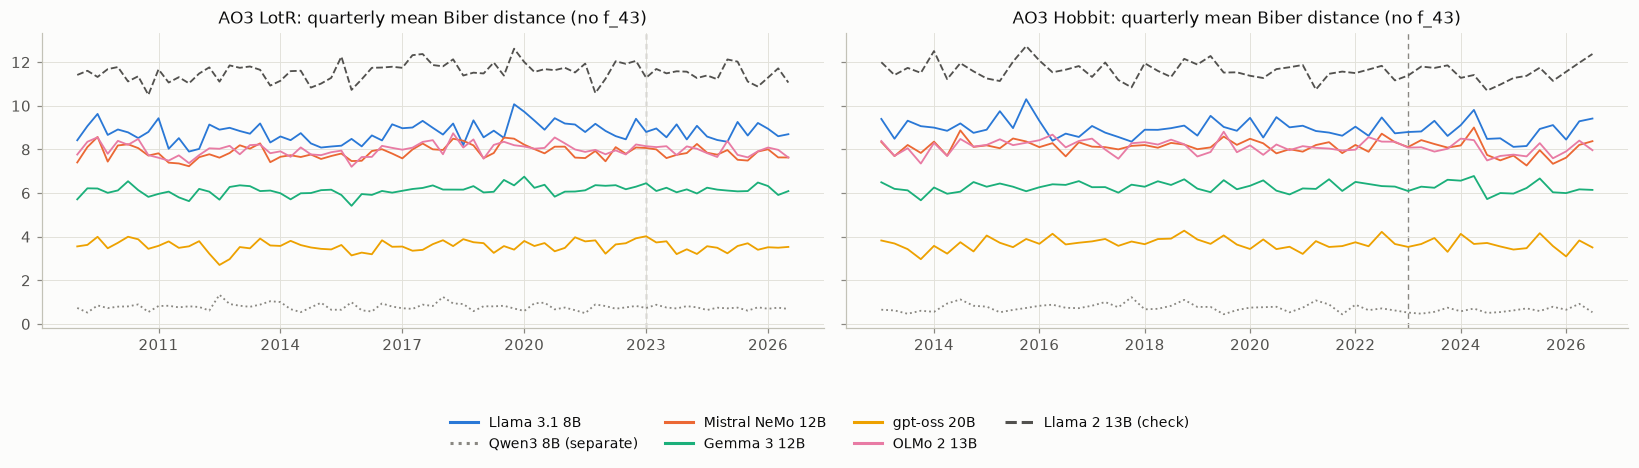

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, group in zip(axes, ["lotr", "hobbit"]):
    data = series[(series["variant"] == "all") & (series["group"] == group)]
    for m in MODELS:
        line = data[data["model"] == m].sort_values("time")
        ax.plot(line["time"], line["biber_no_f43"], color=COLOR[m], ls=DASH[m], lw=1.2)
    mark_break(ax, 2023.0)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))
    ax.set_title(f"{GROUPS[group]}: quarterly mean Biber distance (no f_43)")
model_legend(fig, y=0.02)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

<!-- obs:its -->
**What we see:**
- **ACL:** the largest level changes are Llama 3.1 (−0.97), Mistral (−0.90) and OLMo (−0.70) on the Biber
  distance. For all three the 2023 break is larger than every placebo break (placebo p 0.14, the minimum
  with ACL's ten pre-break years). After correction the edit rate and overlap breaks are significant for all
  three, and the Biber distance for Llama 3.1 and OLMo (Mistral: adjusted p 0.11).
- Gemma (−0.29) and gpt-oss (−0.24) jump less, and not beyond their placebos.
- **AO3:** no main model has a break in either group; the quarterly series are flat. The only significant AO3
  series is Qwen3 in Hobbit (−0.22), the model reported separately.
- **16 of 105 series pass with all texts, 0 of 95 without the short, long and copied outputs.** That is a
  threshold effect, not a different result: the ACL level changes stay the same (Llama 3.1 −0.88, OLMo −0.70;
  raw p 0.003–0.004), but the correction then runs over a different family of tests (Qwen3's AO3 quarters
  become too thin), and the adjusted p-values land at 0.051–0.06 instead of 0.03–0.05. With 12 yearly
  points and two post years, this test sits at the edge of what it can show.

---
## 5. Regressions: the post-2023 effect per model and pooled

Per text: `change ~ post + time + stratum (+ group) (+ log length ratio)`, where `post` is 1 from the
break on. Per model this is OLS with HC3 errors; **pooled** is a mixed model over the five main models with a
random intercept per text (`+ model`). Every fit is done with and without the log length ratio (output words
/ original words): the paraphrase length is partly the change itself, so the estimate with it is the
cautious one. Whiskers are 95% intervals.

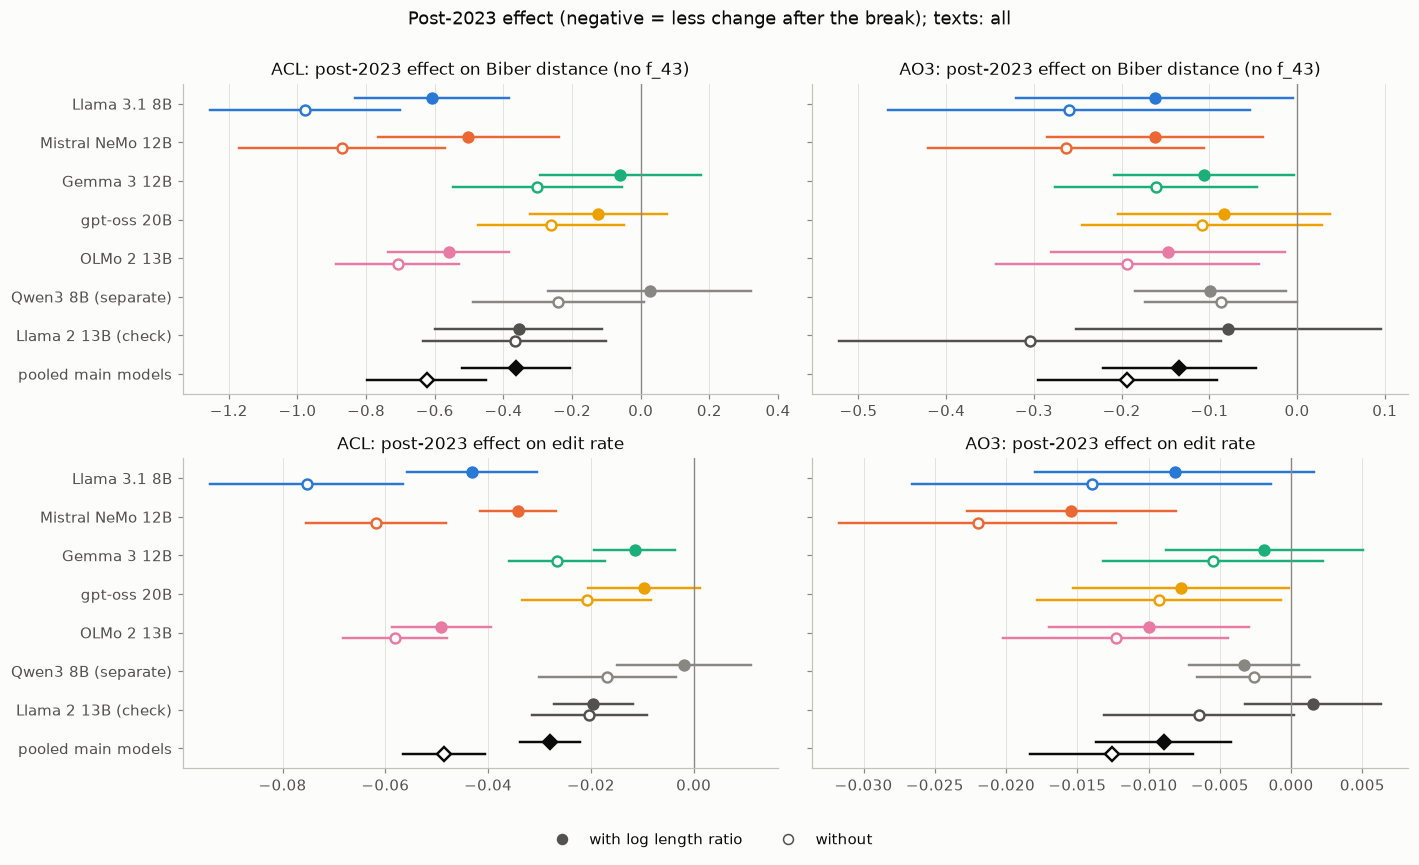

In [12]:
def forest(variant="all"):
    data = regressions[regressions["variant"] == variant]
    rows = MAIN + ["qwen3-8b", "llama-2-13b", "main (pooled)"]
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharey=True)
    for col, corpus in enumerate(["acl", "ao3"]):
        for row, measure in enumerate(["biber_no_f43", "edit"]):
            ax = axes[row, col]
            for offset, length in ((-0.15, True), (0.15, False)):
                cell_data = data[(data["corpus"] == corpus) & (data["measure"] == measure) & (data["length"] == length)]
                for y, model in enumerate(rows):
                    r = cell_data[cell_data["model"] == model]
                    if r.empty:
                        continue
                    r = r.iloc[0]
                    color = "#0b0b0b" if model == "main (pooled)" else COLOR[model]
                    ax.plot([r["ci_lower"], r["ci_upper"]], [y + offset] * 2, color=color, lw=1.6)
                    ax.plot(r["estimate"], y + offset, "D" if model == "main (pooled)" else "o", ms=6.5,
                            color=color if length else "#fcfcfb", markeredgecolor=color, markeredgewidth=1.6)
            ax.axvline(0, color="#898781", lw=0.9)
            ax.set_yticks(range(len(rows)), [model_label(m) if m in LABEL else "pooled main models" for m in rows])
            ax.grid(axis="y", visible=False)
            ax.set_title(f"{corpus.upper()}: post-2023 effect on {MEASURE[measure]}")
    axes[0, 0].invert_yaxis()                                 # shared axis: invert once
    handles = [Line2D([], [], marker="o", ls="", color="#52514e", ms=6.5, label="with log length ratio"),
               Line2D([], [], marker="o", ls="", markerfacecolor="#fcfcfb", markeredgecolor="#52514e", ms=6.5,
                      label="without")]
    fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.02))
    fig.suptitle(f"Post-2023 effect (negative = less change after the break); texts: {variant}", y=1.0)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()


forest()

In [13]:
pooled = regressions[regressions["estimator"] == "mixed"].copy()
pooled["cell"] = [f"{r.estimate:+.3f} [{r.ci_lower:+.3f}, {r.ci_upper:+.3f}]{stars(r.p_adjusted)}"
                  for r in pooled.itertuples()]
table = pooled.pivot_table(index=["corpus", "measure"], columns=["variant", "length"], values="cell", aggfunc="first")
table = table.reindex(columns=[("all", True), ("all", False), ("without_short_long_copy", True),
                               ("without_short_long_copy", False)])
table.columns = ["all texts, with length", "all texts, without length", "no short/long/copy, with length",
                 "no short/long/copy, without length"]
table.index = [f"{c.upper()} | {MEASURE[m]}" for c, m in table.index]
print("Pooled main models (mixed model): post effect [95% CI]; stars: BH-adjusted p")
display(table)
print("converged:", int(pooled["converged"].sum()), "of", len(pooled))

Pooled main models (mixed model): post effect [95% CI]; stars: BH-adjusted p


,"all texts, with length","all texts, without length","no short/long/copy, with length","no short/long/copy, without length"
ACL | Biber distance,"-0.367 [-0.523, -0.211]***","-0.628 [-0.800, -0.456]***","-0.343 [-0.497, -0.189]***","-0.603 [-0.772, -0.435]***"
ACL | Biber distance (no f_43),"-0.363 [-0.519, -0.206]***","-0.624 [-0.796, -0.452]***","-0.338 [-0.492, -0.184]***","-0.593 [-0.761, -0.424]***"
ACL | Dimension 1–6 distance,"-0.059 [-0.249, +0.132]","-0.235 [-0.432, -0.038]*","-0.022 [-0.212, +0.169]","-0.198 [-0.394, -0.002]*"
ACL | edit rate,"-0.028 [-0.034, -0.022]***","-0.048 [-0.056, -0.041]***","-0.026 [-0.031, -0.020]***","-0.047 [-0.054, -0.039]***"
ACL | overlap (8-grams kept),"+0.027 [+0.021, +0.033]***","+0.040 [+0.033, +0.046]***","+0.024 [+0.019, +0.029]***","+0.037 [+0.031, +0.042]***"
AO3 | Biber distance,"-0.135 [-0.222, -0.047]**","-0.201 [-0.304, -0.098]***","-0.133 [-0.219, -0.048]**","-0.207 [-0.307, -0.106]***"
AO3 | Biber distance (no f_43),"-0.134 [-0.221, -0.047]**","-0.193 [-0.296, -0.091]***","-0.132 [-0.217, -0.047]**","-0.205 [-0.304, -0.105]***"
AO3 | Dimension 1–6 distance,"-0.210 [-0.351, -0.069]**","-0.273 [-0.422, -0.123]***","-0.211 [-0.356, -0.067]**","-0.281 [-0.433, -0.129]***"
AO3 | edit rate,"-0.009 [-0.014, -0.004]***","-0.013 [-0.018, -0.007]***","-0.007 [-0.012, -0.003]**","-0.012 [-0.018, -0.007]***"
AO3 | overlap (8-grams kept),"+0.011 [+0.006, +0.016]***","+0.013 [+0.007, +0.019]***","+0.007 [+0.002, +0.011]**","+0.010 [+0.005, +0.014]***"


converged: 40 of 40


<!-- obs:regressions -->
**What we see:**
- **ACL, pooled main models:** the Biber distance (no `f_43`) drops by 0.36 after the break (95% CI 0.21–0.52)
  with the length covariate, and by 0.62 without it. The edit rate drops by 2.8 (4.8) percentage points and
  overlap rises by 2.7 (4.0). The Dimension distance falls only without the length covariate (−0.24).
- **Per model (ACL):** Llama 3.1 (−0.61), Mistral (−0.50) and OLMo (−0.56) drop clearly (p < 0.001); Gemma
  (−0.06) and gpt-oss (−0.12) do not.
- **Llama 2 drops as well** (−0.36, p < 0.05). Its pretraining data ends before ChatGPT, so the drop is not
  explained by the newer models having seen 2023–2024 papers in training.
- **AO3, pooled:** a small drop (Biber −0.13, CI 0.05–0.22; edit rate −0.9 points; Dimension −0.21). With
  thousands of texts per model this is significant, but no model shows a break in its series, and per model
  only Mistral (−0.16) passes.
- **Length** takes about 40% of the ACL effect (−0.62 → −0.36): after the break the paraphrases also stay
  closer to their originals' length. Since keeping the length is part of changing less, the estimate with the
  covariate is the cautious one.
- All 40 mixed models converged.

---
## 6. Sensitivity checks

Everything above is computed again **without the outputs flagged short, long or copied** (the check's
provisional bands: under half or over 1.5 times the original's words, or at least 80% of its 8-word
sequences kept). These outputs stayed in the main analysis because they are amounts of change; dropping them
shows whether the result hangs on them. The table in section 5 already compares the pooled estimates; here
are the per-model effects side by side.

In [14]:
ols = regressions[(regressions["estimator"] == "ols") & regressions["length"]
                  & (regressions["measure"] == "biber_no_f43")].copy()
ols["cell"] = [cell(r.estimate, r.p_adjusted) for r in ols.itertuples()]
table = ols.pivot_table(index=["corpus", "model"], columns="variant", values="cell", aggfunc="first")
table = table.reindex([(c, m) for c in ["acl", "ao3"] for m in MODELS])
table.index = [f"{c.upper()} | {model_label(m)}" for c, m in table.index]
print("Per-model post effect on the Biber distance (no f_43), with the length covariate")
display(table)

Per-model post effect on the Biber distance (no f_43), with the length covariate


variant,all,without_short_long_copy
ACL | Llama 3.1 8B,-0.607***,-0.533***
ACL | Qwen3 8B (separate),+0.026,-0.051
ACL | Mistral NeMo 12B,-0.502***,-0.441**
ACL | Gemma 3 12B,-0.059,-0.064
ACL | gpt-oss 20B,-0.124,-0.148
ACL | OLMo 2 13B,-0.560***,-0.567***
ACL | Llama 2 13B (check),-0.356*,-0.423**
AO3 | Llama 3.1 8B,-0.162,-0.154
AO3 | Qwen3 8B (separate),-0.099,-0.236
AO3 | Mistral NeMo 12B,-0.162*,-0.166*


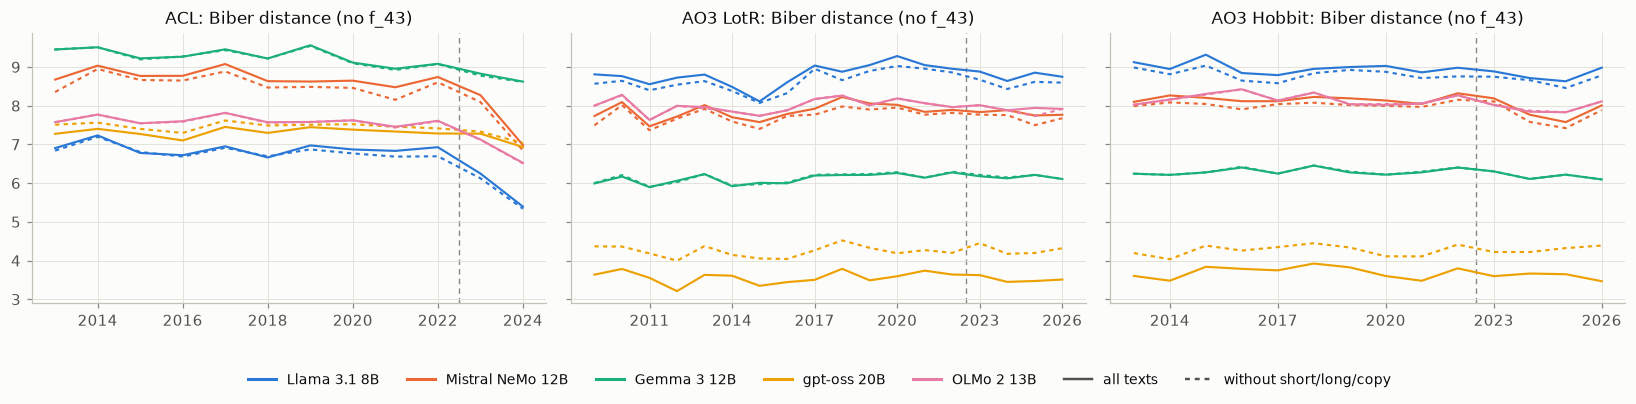

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
data = yearly[(yearly["measure"] == "biber_no_f43") & yearly["model"].isin(MAIN)]
for ax, group in zip(axes, GROUPS):
    for m in MAIN:
        for variant, dash in (("all", "-"), ("without_short_long_copy", (0, (2, 2)))):
            line = data[(data["group"] == group) & (data["model"] == m) & (data["variant"] == variant)].sort_values("year")
            ax.plot(line["year"], line["mean"], color=COLOR[m], ls=dash, lw=1.4)
    mark_break(ax, 2022.5)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
    ax.set_title(f"{GROUPS[group]}: Biber distance (no f_43)")
handles = [Line2D([], [], color=COLOR[m], lw=2, label=LABEL[m]) for m in MAIN]
handles += [Line2D([], [], color="#52514e", ls="-", label="all texts"),
            Line2D([], [], color="#52514e", ls=(0, (2, 2)), label="without short/long/copy")]
fig.legend(handles=handles, loc="upper center", ncol=7, bbox_to_anchor=(0.5, 0.02), fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

<!-- obs:sensitivity -->
**What we see:**
- Dropping the short, long and copied outputs changes almost nothing: pooled ACL −0.34 (all texts −0.36), AO3
  −0.13 (−0.13). Per model the same three ACL families drop (Llama 3.1 −0.53, Mistral −0.44, OLMo −0.57),
  and Llama 2 too (−0.42); in AO3 OLMo (−0.17) now passes alongside Mistral.
- The yearly lines with and without these outputs lie on top of each other, except gpt-oss in AO3, which sits
  higher once its copies are gone.
- Leaving out `f_43` changes little either: `biber` and `biber_no_f43` agree closely (pooled ACL −0.37 vs −0.36).

---
## 7. Cohort MMD²

A distribution-level view: per group and year, one fixed sample of texts (ACL 250, AO3 275 per group; the
same texts for every model, drawn as the most representative of 1,000 draws from the texts every model kept
with complete features). MMD² compares the originals with their paraphrases on the run's RBF bandwidth
(ACL σ 7.770, AO3 7.885); lower means the paraphrases stay closer to the originals as a whole. Bands are a
bootstrap over pairs; the null swaps original and paraphrase within random pairs.

AO3 cohorts are 275, not the 300 first planned: with the same texts for every model and complete features,
LotR 2009 has only 278.

The bootstrap bands sit above the points: resampling pairs with replacement repeats texts, which inflates the
biased (V-statistic) MMD², as in the pipeline's own bootstrap. Read the bands as the spread, not as an interval
centred on the value.

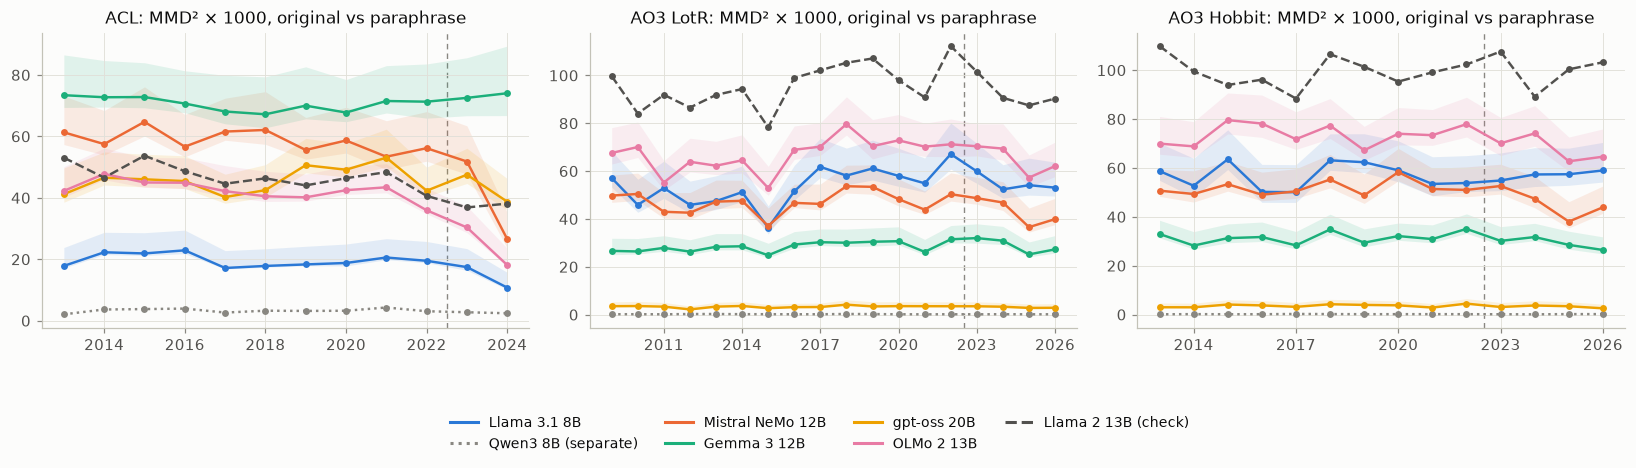

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, group in zip(axes, GROUPS):
    data = cohorts[cohorts["group"] == group]
    for m in MODELS:
        line = data[data["model"] == m].sort_values("year")
        if ROLE[m] == "main":
            ax.fill_between(line["year"], line["ci_lower"] * 1000, line["ci_upper"] * 1000, color=COLOR[m], alpha=0.12, lw=0)
        ax.plot(line["year"], line["mmd2"] * 1000, color=COLOR[m], ls=DASH[m], marker="o", ms=3.5)
    mark_break(ax, 2022.5)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
    ax.set_title(f"{GROUPS[group]}: MMD² × 1000, original vs paraphrase")
model_legend(fig, y=0.02)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

In [17]:
table = (cohorts[cohorts["group"] == "acl"].pivot_table(index="model", columns="year", values="mmd2") * 1000)
table = table.reindex(MODELS).rename(index=model_label)
print("ACL: MMD² x 1000 per year")
display(table.round(1))

rows = mmd_its[mmd_its["measure"] == "mmd2"].copy()
rows["cell"] = [f"{r.level_change * 1000:+.1f}{stars(r.level_p_adjusted)} (adj. p {r.level_p_adjusted:.2f}; "
                f"placebo {r.placebo_p:.2f})" for r in rows.itertuples()]
table = rows.pivot_table(index="model", columns="group", values="cell", aggfunc="first")
print("Interrupted time series of yearly MMD² (level change x 1000)")
display(table.reindex(MODELS).rename(index=model_label)[list(GROUPS)].rename(columns=GROUPS))
print(f"effect (observed - null mean) / null sd: {cohorts['effect'].min():.1f} to {cohorts['effect'].max():.1f}; "
      f"largest adjusted p {cohorts['p_adjusted'].max():.2f}")

ACL: MMD² x 1000 per year


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
model,,,,,,,,,,,,
Llama 3.1 8B,17.8,22.3,21.9,22.9,17.2,17.8,18.3,18.8,20.6,19.5,17.4,10.8
Qwen3 8B (separate),2.1,3.7,3.8,3.9,2.7,3.3,3.2,3.2,4.3,3.1,2.8,2.4
Mistral NeMo 12B,61.3,57.5,64.7,56.6,61.6,62.1,55.6,58.7,53.4,56.1,51.8,26.5
Gemma 3 12B,73.4,72.7,72.8,70.7,68.1,67.2,70.0,67.7,71.5,71.3,72.5,74.0
gpt-oss 20B,41.2,46.5,46.0,45.4,40.2,42.5,50.6,49.1,53.1,42.3,47.5,38.7
OLMo 2 13B,42.2,47.8,45.0,44.9,42.2,40.5,40.2,42.5,43.4,35.9,30.4,18.1
Llama 2 13B (check),53.1,46.6,53.7,48.7,44.6,46.3,44.0,46.4,48.3,40.6,36.9,38.1


Interrupted time series of yearly MMD² (level change x 1000)


group,ACL,AO3 LotR,AO3 Hobbit
model,,,
Llama 3.1 8B,-4.4 (adj. p 0.57; placebo 0.29),-3.8 (adj. p 0.84; placebo 0.40),-1.0 (adj. p 0.94; placebo 1.00)
Qwen3 8B (separate),-1.1 (adj. p 0.57; placebo 0.29),-0.0 (adj. p 0.84; placebo 0.60),-0.1 (adj. p 0.57; placebo 0.33)
Mistral NeMo 12B,-14.8 (adj. p 0.44; placebo 0.14),-0.3 (adj. p 0.98; placebo 1.00),-2.5 (adj. p 0.84; placebo 0.50)
Gemma 3 12B,+4.7 (adj. p 0.44; placebo 0.57),+1.2 (adj. p 0.84; placebo 0.30),-1.5 (adj. p 0.84; placebo 0.50)
gpt-oss 20B,-5.5 (adj. p 0.84; placebo 0.29),-0.1 (adj. p 0.94; placebo 0.80),-0.6 (adj. p 0.84; placebo 0.33)
OLMo 2 13B,-13.6 (adj. p 0.21; placebo 0.14),-3.0 (adj. p 0.84; placebo 0.70),-3.4 (adj. p 0.84; placebo 0.83)
Llama 2 13B (check),-4.4 (adj. p 0.66; placebo 0.14),-6.8 (adj. p 0.84; placebo 0.50),+2.1 (adj. p 0.94; placebo 0.83)


effect (observed - null mean) / null sd: 1.1 to 165.8; largest adjusted p 0.14


<!-- obs:mmd -->
**What we see:**
- **ACL:** MMD² falls in 2024 for the same three families: Mistral 56.1 (2022) → 51.8 → 26.5, OLMo
  35.9 → 30.4 → 18.1 and Llama 3.1 19.5 → 17.4 → 10.8 (× 1000). Gemma stays flat or rises (71.3 → 74.0),
  gpt-oss moves without a direction (42.3, 47.5, 38.7), and Llama 2 declines from 2021 (48.3 → 38.1).
- **AO3:** flat in both groups.
- **No yearly MMD² series is significant after correction** (smallest adjusted p 0.21, OLMo in ACL). Mistral,
  OLMo and Llama 2 again reach the minimum placebo p (0.14). One number per year, 12 years and two post years
  give this test little power; the per-text regressions carry the evidence.
- Every cohort differs from its originals far beyond the swap null (1.1 to 166 null sds; Qwen3 the lowest),
  so MMD² itself, not the effect, is the measure to follow over the years.

---
## 8. Which features the models change

The mean signed change (paraphrase minus original, in z-scores) of each feature, over all kept texts. Red:
the paraphrases have more of the feature than the originals; blue: less. The 20 features with the largest
mean absolute change over the main models are shown per corpus. This is descriptive only (no per-feature
tests); it is also the raw material of the "LLM direction" (section 9).

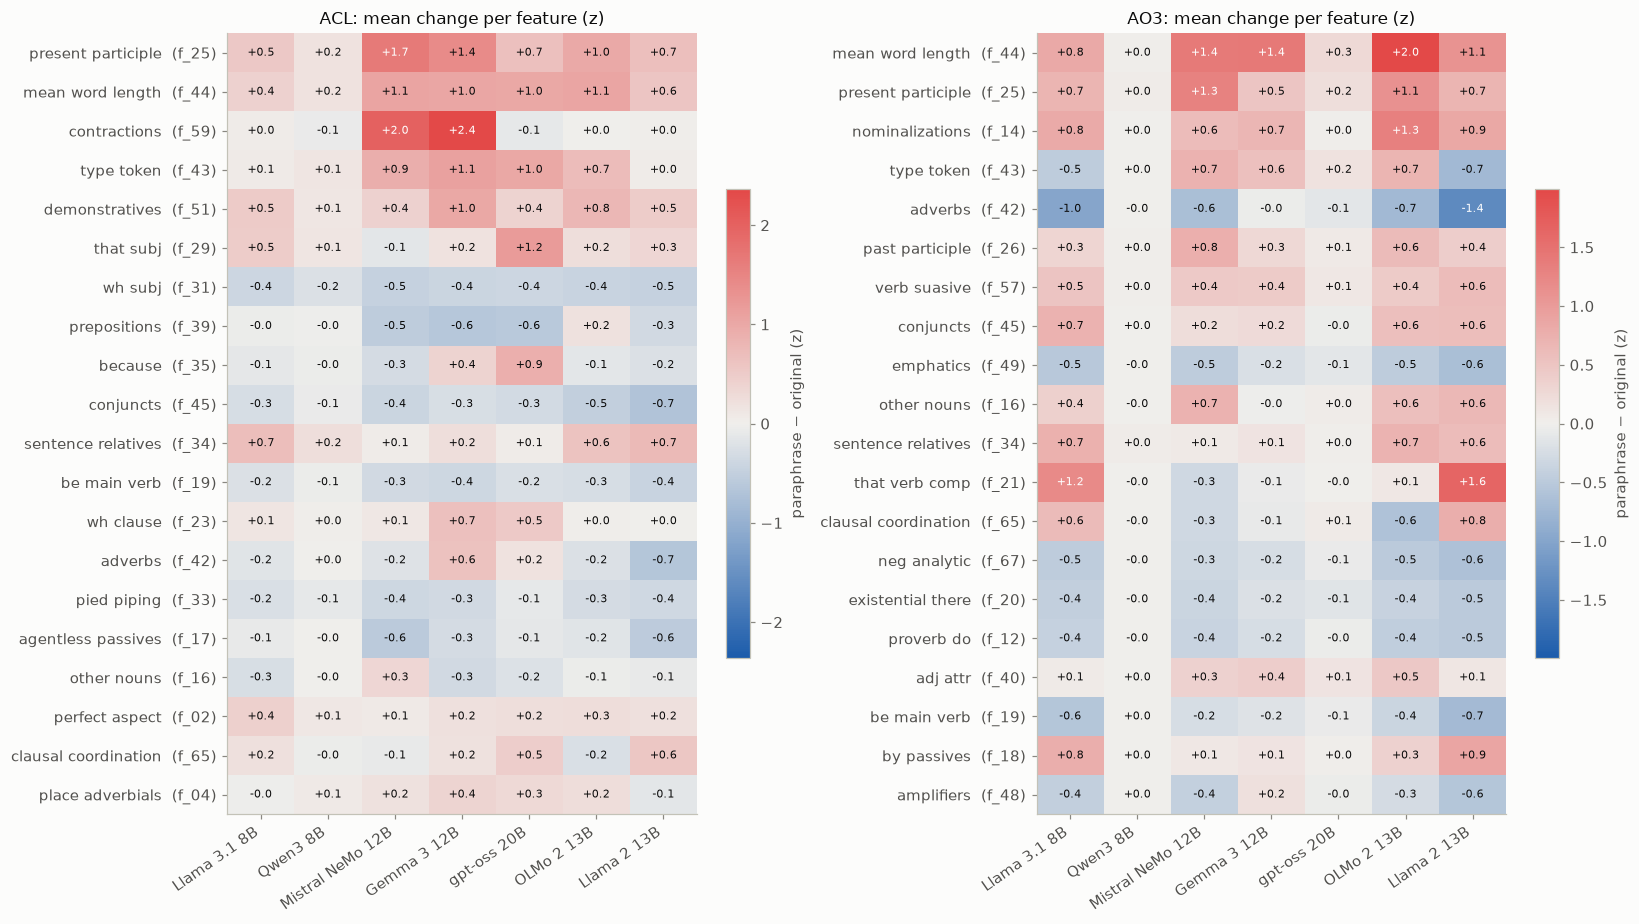

In [18]:
differences = {key: pd.read_parquet(RESULTS / "differences" / f"{key}.parquet") for key in MODELS}
corpus_of = texts.drop_duplicates("item_id").set_index("item_id")["corpus"]
fig, axes = plt.subplots(1, 2, figsize=(15, 8.5))
for ax, corpus in zip(axes, ["acl", "ao3"]):
    means = pd.DataFrame({m: d[d.index.map(corpus_of) == corpus].filter(like="f_").mean() for m, d in differences.items()})
    top = means[MAIN].abs().mean(axis=1).sort_values(ascending=False).index[:20]
    data = means.loc[top, MODELS]
    limit = np.nanmax(np.abs(data.to_numpy()))
    image = ax.imshow(data.to_numpy(), cmap=DIVERGING, norm=TwoSlopeNorm(0, -limit, limit), aspect="auto")
    ax.set_xticks(range(len(MODELS)), [LABEL[m] for m in MODELS], rotation=35, ha="right")
    ax.set_yticks(range(len(top)), [f.split("_", 2)[-1].replace("_", " ") + f"  ({f[:4]})" for f in top])
    ax.grid(False)
    for (i, j), value in np.ndenumerate(data.to_numpy()):
        ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if abs(value) > 0.6 * limit else "#0b0b0b")
    ax.set_title(f"{corpus.upper()}: mean change per feature (z)")
    fig.colorbar(image, ax=ax, shrink=0.6, label="paraphrase − original (z)")
fig.tight_layout()
plt.show()

In [19]:
dims = [c for c in next(iter(differences.values())).columns if c.startswith("Dim")]
rows = []
for m, d in differences.items():
    for corpus in ["acl", "ao3"]:
        part = d[d.index.map(corpus_of) == corpus][dims].mean()
        rows.append({"model": model_label(m), "corpus": corpus.upper(), **{c.split("_")[0]: v for c, v in part.items()}})
print("Mean change of the Dimension scores (paraphrase - original)")
display(pd.DataFrame(rows).set_index(["corpus", "model"]).sort_index(level=0, sort_remaining=False).round(2))

Mean change of the Dimension scores (paraphrase - original)


Dim1  Dim2  Dim3  Dim4  Dim5  Dim6
corpus model                                                  
ACL    Llama 3.1 8B        -0.13  0.48 -0.17  0.17 -0.20  0.28
       Qwen3 8B (separate) -0.28  0.10 -0.26 -0.09 -0.03  0.06
       Mistral NeMo 12B    -0.45  0.76 -0.44 -0.36 -0.48  0.11
       Gemma 3 12B          2.36  1.12 -1.30  0.22 -0.18  0.53
       gpt-oss 20B          0.20  0.55 -0.63 -0.17 -0.27  0.38
       OLMo 2 13B          -2.49  0.47 -0.52 -0.36 -0.32  0.42
       Llama 2 13B (check)  0.53  0.29  0.24  0.26 -0.81  0.26
AO3    Llama 3.1 8B        -3.81  0.47  1.04  0.28  0.96  0.53
       Qwen3 8B (separate)  0.01  0.04 -0.02  0.02  0.02 -0.00
       Mistral NeMo 12B    -3.89  0.47  0.36 -0.14  0.38 -0.36
       Gemma 3 12B         -1.79  0.22  0.05  0.48  0.35 -0.06
       gpt-oss 20B         -0.26  0.24 -0.05  0.04 -0.01 -0.02
       OLMo 2 13B          -5.50  0.16  0.85 -0.04  0.78  0.04
       Llama 2 13B (check) -5.10  0.42  1.62  0.02  0.85  0.61

Did the per-feature change shrink after 2023? Mean absolute change per feature, averaged over the main models,
before (up to 2022) and after (from 2023), ACL. The ten features whose change shrank most:

In [20]:
data = features_yearly[(features_yearly["group"] == "acl") & features_yearly["model"].isin(MAIN)
                       & features_yearly["feature"].str.startswith("f_")]
data = data.assign(era=np.where(data["year"] >= 2023, "from 2023", "to 2022"))
era = data.groupby(["feature", "era"])["mean_abs"].mean().unstack("era")[["to 2022", "from 2023"]]
era["shrink"] = era["from 2023"] - era["to 2022"]
display(era.sort_values("shrink").head(10).round(3))
print(f"{int((era['shrink'] < 0).sum())} of {len(era)} features change less from 2023 on (ACL, main models)")

era,to 2022,from 2023,shrink
feature,,,
f_31_wh_subj,0.552,0.265,-0.287
f_44_mean_word_length,1.043,0.792,-0.252
f_43_type_token,0.916,0.731,-0.185
f_33_pied_piping,0.472,0.305,-0.167
f_25_present_participle,1.322,1.176,-0.146
f_58_verb_seem,0.330,0.193,-0.138
f_05_time_adverbials,0.634,0.509,-0.125
f_47_hedges,0.221,0.103,-0.118
f_17_agentless_passives,0.660,0.543,-0.117


60 of 67 features change less from 2023 on (ACL, main models)


<!-- obs:features -->
**What we see:**
- **ACL:** all main models lengthen words (mean word length +0.4 to +1.1 z) and add present participles
  (+0.5 to +1.7). Mistral and Gemma add contractions (+2.0, +2.4), which also lifts Gemma's Dimension 1
  (+2.4); OLMo lowers it (−2.5). Wh-relative subjects go down for every model, prepositions for three of
  the five.
- **AO3:** longer words (+0.3 to +2.0), more present participles and nominalizations; fewer adverbs,
  emphatics and analytic negations. **Dimension 1 (involved → informational) falls strongly** for Llama 3.1,
  Mistral and OLMo (−3.8 to −5.5) and for Llama 2 (−5.1): the paraphrases make fiction more informational.
- **After 2023, 60 of 67 features change less** in ACL papers (main models). The largest shrinkage is in
  wh-relative subjects (0.55 → 0.27 z), mean word length (1.04 → 0.79) and the type-token ratio
  (0.92 → 0.73), two of the features the paraphrases push hardest. Whether the newer papers already moved in
  the models' direction is the question of the "LLM direction" (section 9).